# Introducción a PyMC y ArviZ

En esta notebook vamos a escribir un modelo bayesiano en PyMC, obtener muestras mediante MCMC y evaluar su calidad con ArviZ. Después usaremos esas muestras para hacer inferencia y generar observaciones futuras.

Retomamos los tiros libres de Caleb Wilson: **17 aciertos en 23 intentos**. Como conocemos el _posterior_ exacto, podemos comparar los resultados de MCMC con una referencia analítica mientras aprendemos las herramientas.

## Preparación

La celda siguiente deja una instalación opcional comentada para un entorno nuevo. Si la necesitás, quitá el comentario y ejecutala antes de importar los paquetes. Si ya estaban importados, reiniciá el kernel después de instalar. La instalación en Colab puede depender de las versiones de Python y de los paquetes disponibles allí.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import preliz as pz
import pymc as pm
import xarray as xr

COLORES = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]
SEMILLA = 2026

az.rcParams["plot.backend"] = "matplotlib"
az.rcParams["stats.ci_kind"] = "eti"
az.rcParams["stats.ci_prob"] = 0.95

print("PyMC:", pm.__version__)
print("ArviZ:", az.__version__)
print("PreliZ:", pz.__version__)
print("xarray:", xr.__version__)

PyMC: 6.3.2
ArviZ: 1.3.0
PreliZ: 0.28.0
xarray: 2026.9.0


## ¿Qué hacen PyMC y ArviZ?

[**PyMC**](https://www.pymc.io/projects/docs/en/stable/learn.html) permite escribir un modelo probabilístico mediante variables y distribuciones conectadas entre sí. A partir de ese modelo y de los datos, puede construir cadenas de Markov para aproximar el _posterior_. También permite simular datos del modelo.

[**ArviZ**](https://python.arviz.org/en/stable/user_guide/migration_guide.html) permite examinar las muestras: visualizar las cadenas, calcular diagnósticos y resumir distribuciones. Vamos a usarlo para decidir si contamos con una aproximación adecuada y con suficiente precisión para las preguntas que queremos responder.

PreliZ nos sigue sirviendo para trabajar con distribuciones conocidas y sus funciones de densidad, masa y distribución. En PyMC, las distribuciones nombradas forman parte de un modelo y pueden depender de otras variables desconocidas. PyTensor representa esas relaciones como un grafo computacional y permite calcular los gradientes que utiliza NUTS.

## Los tiros libres de Caleb

Usamos los mismos datos de la clase anterior, fijados para este ejemplo. $Y$ es la cantidad de aciertos y $\theta$ la probabilidad de encestar un tiro libre. Suponemos independencia entre tiros dado $\theta$ y una probabilidad constante durante el período observado y el período que queremos predecir.

$$
\begin{aligned}
Y\mid\theta &\sim \operatorname{Binomial}(n,\theta),\qquad n=23,\quad y=17,\\
\theta &\sim \operatorname{Beta}(1,1).
\end{aligned}
$$

La conjugación nos da $\theta\mid y\sim\operatorname{Beta}(18,7)$, cuya media es $18/25=0.72$. Vamos a conservar esta distribución como referencia. **¿Podemos recuperar sus resúmenes sin usar la actualización conjugada en el muestreo?**

In [2]:
n_caleb = 23
y_caleb = 17
alpha_prior = 1
beta_prior = 1

alpha_posterior = alpha_prior + y_caleb
beta_posterior = beta_prior + n_caleb - y_caleb
posterior_exacto = pz.Beta(alpha=alpha_posterior, beta=beta_posterior)

Primero escribimos el modelo en PyMC. Registramos la cantidad de intentos mediante `pm.Data`: es una cantidad conocida que más adelante podremos cambiar para predecir un nuevo conjunto de tiros.

In [3]:
with pm.Model() as modelo:
    n_intentos = pm.Data("n_intentos", n_caleb)
    theta = pm.Beta("theta", alpha=alpha_prior, beta=beta_prior)
    y = pm.Binomial("y", n=n_intentos, p=theta, observed=y_caleb)

modelo

n_intentos = Data(23)
     theta ~ Beta(1, 1)
         y ~ Binomial(23, theta)

El bloque `with pm.Model() as modelo` crea un modelo y hace que PyMC registre las variables definidas dentro de él.

- `pm.Data("n_intentos", n_caleb)` registra el número conocido de tiros. El nombre entre comillas identifica esa cantidad dentro del modelo.
- `pm.Beta("theta", ...)` registra el _prior_ de la probabilidad desconocida. `theta` es una variable simbólica con la que podemos construir otras expresiones.
- `pm.Binomial("y", ...)` registra el modelo observacional. El argumento `observed=y_caleb` fija los aciertos observados y aporta la verosimilitud. En la API de la binomial, `p` corresponde a nuestro $\theta$.

Hasta acá especificamos el modelo. Todavía no obtuvimos muestras del _posterior_.

## Obtener muestras con NUTS

`pm.sample()` ejecuta MCMC. Para este modelo usamos **NUTS**, una variante de HMC que elige la longitud de las trayectorias durante la exploración. Durante el calentamiento también se adaptan el tamaño de paso y la matriz de masa.

Con `chains=4`, `tune=1000` y `draws=1000` pedimos cuatro cadenas, cada una con 1000 iteraciones de calentamiento y 1000 extracciones posteriores. El calentamiento se descarta de los resúmenes. Entonces tendremos **4000 extracciones conservadas**, que pueden presentar dependencia dentro de cada cadena.

`nuts_sampler="pymc"` selecciona explícitamente la implementación de NUTS de PyMC. Dejamos que PyMC determine cuántas cadenas ejecutar en paralelo según los recursos disponibles. En los mensajes de la ejecución podemos consultar cuántos procesos utilizó. `random_seed=SEMILLA` fija la semilla para poder reproducir el muestreo dentro del mismo entorno.

In [4]:
with modelo:
    idata = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        nuts_sampler="pymc",
        random_seed=SEMILLA,
    )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [theta]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.


## ¿Dónde están las muestras?

El resultado `idata` es un `xarray.DataTree`: organiza la información en grupos. El nombre `idata` es una elección nuestra para la variable de Python.

| Grupo | Contenido |
| --- | --- |
| `posterior` | Extracciones de los parámetros después del calentamiento. |
| `sample_stats` | Información del muestreador, como divergencias y energía. |
| `observed_data` | Los valores observados. |
| `constant_data` | Cantidades conocidas registradas con `pm.Data`. |

Veamos el árbol y luego las muestras de `theta`.

In [5]:
idata

<xarray.DataTree>
Group: /
├── Group: /posterior
│       Dimensions:  (chain: 4, draw: 1000)
│       Coordinates:
│         * chain    (chain) int64 32B 0 1 2 3
│         * draw     (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
│       Data variables:
│           theta    (chain, draw) float64 32kB 0.6621 0.6443 0.7916 ... 0.5079 0.6265
│       Attributes:
│           created_at:                 2026-11-27T22:09:51.104512+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.2
│           sample_dims:                ['chain', 'draw']
│           sampling_time:              2.1996841430664062
│           tuning_steps:               1000
├── Group: /sample_stats
│       Dimensions:                (chain: 4, draw: 1000)
│       Coordinates:
│         * chain                  (chain) int64 32B 0 1 2 3
│         * draw                   (draw) int64 8kB 0 1 2 3 4 5 ... 995 996 997 998 999
│       Data variables: (12/18)
│           perf_counter_start     (chain, draw) float64 32kB 3.255e+04 ... 3.255e+04
│           lp                     (chain, draw) float64 32kB -3.495 -3.626 ... -3.789
│           acceptance_rate        (chain, draw) float64 32kB 0.379 0.8991 ... 1.0
│           energy                 (chain, draw) float64 32kB 4.384 3.789 ... 5.9 4.931
│           smallest_eigval        (chain, draw) float64 32kB nan nan nan ... nan nan
│           diverging              (chain, draw) bool 4kB False False ... False False
│           ...                     ...
│           index_in_trajectory    (chain, draw) int64 32kB 0 3 2 0 -1 1 ... 3 1 2 -1 -1
│           max_energy_error       (chain, draw) float64 32kB 0.9702 0.1468 ... -1.001
│           process_time_diff      (chain, draw) float64 32kB 4.601e-05 ... 7.136e-05
│           n_steps                (chain, draw) float64 32kB 1.0 3.0 3.0 ... 3.0 3.0
│           perf_counter_diff      (chain, draw) float64 32kB 4.606e-05 ... 7.129e-05
│           tree_depth             (chain, draw) int64 32kB 1 2 2 1 2 1 ... 1 2 1 2 2 2
│       Attributes:
│           created_at:                 2026-11-27T22:09:51.111148+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.2
│           sample_dims:                ['chain', 'draw']
│           sampling_time:              2.1996841430664062
│           tuning_steps:               1000
├── Group: /observed_data
│       Dimensions:  ()
│       Data variables:
│           y        int64 8B 17
│       Attributes:
│           created_at:                 2026-11-27T22:09:51.113984+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.2
│           sample_dims:                []
└── Group: /constant_data
        Dimensions:     ()
        Data variables:
            n_intentos  float64 8B 23.0
        Attributes:
            created_at:                 2026-11-27T22:09:51.114535+00:00
            creation_library:           ArviZ
            creation_library_version:   1.3.1
            creation_library_language:  Python
            inference_library:          pymc
            inference_library_version:  6.3.2
            sample_dims:                []

In [6]:
theta_muestras = idata["posterior"]["theta"]
theta_muestras

<xarray.DataArray 'theta' (chain: 4, draw: 1000)> Size: 32kB
array([[0.66205745, 0.64431523, 0.79164629, ..., 0.75997891, 0.75997891,
        0.86217865],
       [0.66654564, 0.77510966, 0.74790773, ..., 0.78935322, 0.62920295,
        0.82196049],
       [0.79210056, 0.8608638 , 0.69167124, ..., 0.7471779 , 0.79070212,
        0.76383768],
       [0.84197989, 0.76614781, 0.72977478, ..., 0.63229074, 0.50791462,
        0.6264611 ]], shape=(4, 1000))
Coordinates:
  * chain    (chain) int64 32B 0 1 2 3
  * draw     (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999

Una variable del árbol es un `xarray.DataArray`, un arreglo con dimensiones nombradas y coordenadas. Para `theta`, las dimensiones son `chain` y `draw`: indican la cadena y la posición dentro de ella.

El grupo `idata["posterior"]` es un nodo del árbol. Su método `.to_dataset()` obtiene un `xarray.Dataset`, que puede reunir varias variables. Consultemos las longitudes de los ejes y seleccionemos las primeras cinco extracciones de una cadena con `.isel()`, que selecciona por posición.

In [7]:
print(type(idata))
print(theta_muestras.sizes)
display(theta_muestras.isel(chain=0, draw=slice(0, 5)))
idata["posterior"].to_dataset()

<class 'xarray.core.datatree.DataTree'>
Frozen({'chain': 4, 'draw': 1000})


<xarray.DataArray 'theta' (draw: 5)> Size: 40B
array([0.66205745, 0.64431523, 0.79164629, 0.79164629, 0.78490465])
Coordinates:
  * draw     (draw) int64 40B 0 1 2 3 4
    chain    int64 8B 0

<xarray.Dataset> Size: 40kB
Dimensions:  (chain: 4, draw: 1000)
Coordinates:
  * chain    (chain) int64 32B 0 1 2 3
  * draw     (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
Data variables:
    theta    (chain, draw) float64 32kB 0.6621 0.6443 0.7916 ... 0.5079 0.6265
Attributes:
    created_at:                 2026-11-27T22:09:51.104512+00:00
    creation_library:           ArviZ
    creation_library_version:   1.3.1
    creation_library_language:  Python
    inference_library:          pymc
    inference_library_version:  6.3.2
    sample_dims:                ['chain', 'draw']
    sampling_time:              2.1996841430664062
    tuning_steps:               1000

Para resumir por cadena, reducimos solo `draw`. Para resumir el conjunto completo, reducimos `chain` y `draw`. Conviene **conservar ambos ejes al calcular diagnósticos**, porque la separación entre cadenas y el orden de las extracciones contienen información necesaria.

Si necesitamos NumPy, `.to_numpy()` devuelve los valores y conserva la forma del arreglo, aunque se pierden los nombres de dimensiones y coordenadas.

In [8]:
display(theta_muestras.mean("draw"))
print("Forma del array de NumPy:", theta_muestras.to_numpy().shape)

<xarray.DataArray 'theta' (chain: 4)> Size: 32B
array([0.72495958, 0.72082055, 0.72679404, 0.71686601])
Coordinates:
  * chain    (chain) int64 32B 0 1 2 3

Forma del array de NumPy: (4, 1000)


## Evaluar las cadenas

**¿Las muestras representan adecuadamente el _posterior_? ¿Con qué precisión podemos estimar sus resúmenes?** Primero buscamos señales de problemas de exploración y después evaluamos el error de Monte Carlo. Una ejecución finita y sus diagnósticos aportan evidencia, pero no prueban que se haya explorado toda la distribución.

Empecemos por las **trazas**. `az.plot_trace_dist()` muestra la distribución de las extracciones de cada cadena y sus valores en orden de iteración. Buscamos cadenas que recorran regiones similares, sin tendencias persistentes ni largos períodos atrapadas en una zona.

Con `compact=False` y `color=COLORES` distinguimos las cadenas mediante los colores del curso. La función devuelve un `PlotCollection`, que organiza los paneles y sus elementos visuales. Lo guardamos en `trazas` y usamos `.add_legend("chain")` para identificar cada cadena en la leyenda.

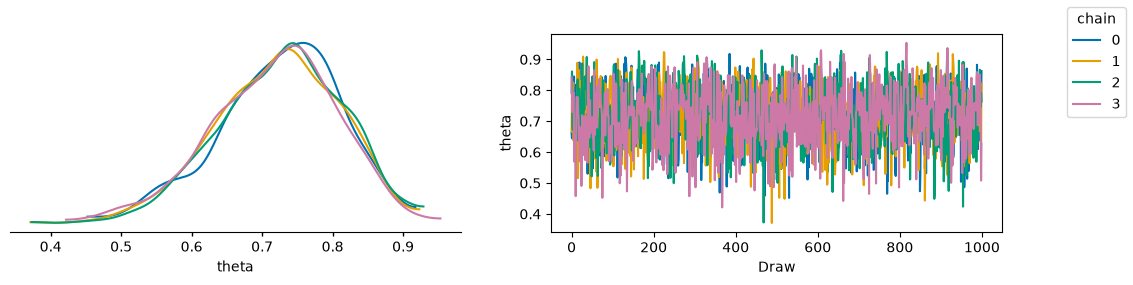

In [9]:
trazas = az.plot_trace_dist(idata, var_names="theta", compact=False, color=COLORES)
trazas.add_legend("chain");

La comparación de densidades ayuda a ver si las cadenas asignan pesos parecidos a las distintas regiones. Las trazas permiten ver cómo las recorrieron. Ambas vistas se complementan: densidades similares también pueden aparecer cuando las cadenas se desplazan lentamente.

La **autocorrelación** compara extracciones de una cadena separadas por un rezago $k$. Con `max_lag=30` examinamos hasta 30 posiciones de separación. Una autocorrelación positiva que persiste muchos rezagos implica que promediar más extracciones aporta menos precisión que en una muestra independiente del mismo tamaño.

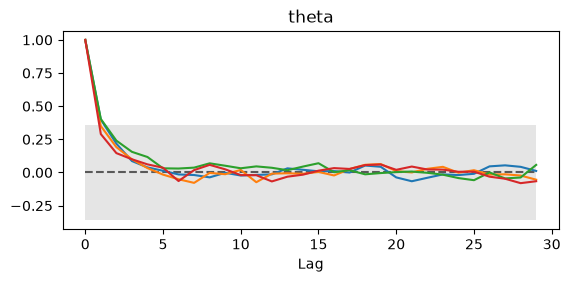

In [10]:
az.plot_autocorr(idata, var_names="theta", max_lag=30);

**$\hat R$: comparación entre cadenas.** ArviZ usa por defecto la versión basada en rangos y cadenas divididas, que ayuda a detectar diferencias de ubicación y escala y cambios entre las mitades de las cadenas.

Buscamos valores cercanos a 1. Un valor mayor que 1.01 es una señal para revisar el muestreo. Un resultado cercano a 1 se interpreta junto con las trazas y los demás diagnósticos: varias cadenas podrían haber dejado sin visitar una misma región.

In [11]:
rhat_theta = az.rhat(idata, var_names="theta")["theta"].item()
print(f"R-hat: {rhat_theta:.4f}")

R-hat: 1.0024


**ESS: tamaño efectivo de muestra.** El ESS expresa cuántas extracciones independientes aportarían una precisión comparable para un resumen. Con autocorrelación positiva suele ser menor que las 4000 extracciones conservadas. Con dependencia negativa puede ser mayor.

El ESS depende de lo que estimamos. `method="bulk"` evalúa la exploración del centro de la distribución mediante rangos normalizados. `method="tail"` evalúa las colas usando los cuantiles 5% y 95%. Para la media usamos `method="mean"`.

Unos pocos cientos de ESS pueden servir para una primera evaluación, pero la cantidad necesaria depende de la precisión que requiera nuestra pregunta.

In [12]:
ess_bulk = az.ess(idata, var_names="theta", method="bulk")["theta"].item()
ess_tail = az.ess(idata, var_names="theta", method="tail")["theta"].item()
ess_media = az.ess(idata, var_names="theta", method="mean")["theta"].item()

print(f"Extracciones conservadas: {theta_muestras.size}")
print(f"ESS bulk: {ess_bulk:.0f}")
print(f"ESS tail: {ess_tail:.0f}")
print(f"ESS de la media: {ess_media:.0f}")

Extracciones conservadas: 4000
ESS bulk: 1572
ESS tail: 2337
ESS de la media: 1611


**MCSE: error estándar de Monte Carlo.** Cuantifica la variabilidad de un estimador entre repeticiones del muestreo. Para la media, la relación aproximada es

$$
\widehat{\operatorname{MCSE}}(\hat\mu)
\approx \frac{\hat\sigma_\theta}{\sqrt{\widehat{\operatorname{ESS}}_\mu}}.
$$

$\hat\sigma_\theta$ describe la dispersión del _posterior_ de $\theta$. El MCSE describe el error numérico al estimar su media. Más iteraciones pueden reducir el segundo sin reducir la incertidumbre sobre la probabilidad de encestar.

`az.mcse(..., method="mean")` estima el MCSE de la media, teniendo en cuenta la dependencia de las extracciones.

In [13]:
mcse_media = az.mcse(idata, var_names="theta", method="mean")["theta"].item()
sd_theta = theta_muestras.std(dim=("chain", "draw"), ddof=1).item()

print(f"Desvío posterior: {sd_theta:.4f}")
print(f"MCSE de la media: {mcse_media:.5f}")
print(f"Desvío / raíz del ESS de la media: {sd_theta / np.sqrt(ess_media):.5f}")

Desvío posterior: 0.0877
MCSE de la media: 0.00218
Desvío / raíz del ESS de la media: 0.00218


**Diagnósticos de HMC y NUTS.** Las divergencias indican dificultades numéricas al integrar las trayectorias. Pueden acompañar una exploración sesgada, aun con un R-hat cercano a 1. Las contamos en `sample_stats`, donde cada extracción tiene un indicador `diverging`. Al sumar sobre `draw` obtenemos la cantidad de divergencias de cada cadena.

Si aparecen, revisamos el modelo, sus escalas y su parametrización. Una posibilidad es volver a muestrear agregando un valor más alto de `target_accept` a `pm.sample()`: esto puede ayudar al reducir el tamaño de paso, pero hace falta volver a examinar los diagnósticos. También conviene revisar los avisos sobre profundidad máxima del árbol y baja exploración de la energía. Más iteraciones por sí solas pueden mantener el problema.

In [14]:
divergencias = idata["sample_stats"]["diverging"].sum("draw")
print("Divergencias por cadena:")
display(divergencias)

Divergencias por cadena:


<xarray.DataArray 'diverging' (chain: 4)> Size: 32B
array([0, 0, 0, 0])
Coordinates:
  * chain    (chain) int64 32B 0 1 2 3

Podemos reunir los principales resultados con `az.summary()`. Pedimos un **IC central del 95%** de manera explícita mediante `ci_kind="eti"` y `ci_prob=0.95`. Sus extremos son los cuantiles 2.5% y 97.5%.

La tabla incluye media (`mean`), desvío (`sd`), extremos del IC, errores Monte Carlo (`mcse_mean`, `mcse_sd`), tamaños efectivos (`ess_bulk`, `ess_tail`) y `r_hat`. La precisión mostrada se controla con `round_to`; los cálculos conservan la precisión original.

In [15]:
resumen = az.summary(idata, var_names="theta", ci_kind="eti", ci_prob=0.95, round_to=4)
resumen

,mean,sd,eti95_lb,eti95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
theta,0.7224,0.0877,0.5339,0.874,1571.952,2337.3577,1.0024,0.0022,0.0012


## Inferencias a partir del _posterior_

Con las muestras de NUTS podemos estimar la media, un IC central del 95% y una probabilidad como $P(\theta>0.7\mid y)$. Para esta última promediamos el indicador de superar 0.7:

$$
\widehat P(\theta>0.7\mid y)=\frac{1}{N}\sum_{s=1}^{N} \mathbb{I}(\theta_s>0.7).
$$

En xarray, `.mean(dim=("chain", "draw"))` promedia ambos ejes y `.item()` extrae un escalar. `.quantile()` calcula cuantiles empíricos.

In [16]:
media_mcmc = theta_muestras.mean(dim=("chain", "draw")).item()
ic_mcmc = theta_muestras.quantile([0.025, 0.975], dim=("chain", "draw")).to_numpy()
prob_theta_mcmc = (theta_muestras > 0.7).mean(dim=("chain", "draw")).item()

print(f"Media posterior: {media_mcmc:.4f}")
print(f"IC central del 95%: [{ic_mcmc[0]:.4f}, {ic_mcmc[1]:.4f}]")
print(f"P(theta > 0.7 | y): {prob_theta_mcmc:.4f}")

Media posterior: 0.7224
IC central del 95%: [0.5339, 0.8740]
P(theta > 0.7 | y): 0.6242


`az.plot_dist()` muestra la distribución marginal y el intervalo solicitado. En el _posterior_ quedan valores plausibles de la probabilidad de encestar. El ancho de ese intervalo refleja la incertidumbre sobre `theta` bajo los supuestos del modelo.

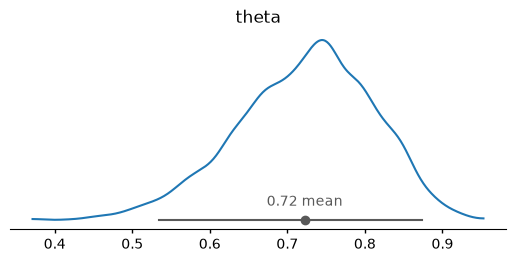

In [17]:
az.plot_dist(idata, var_names="theta", ci_kind="eti", ci_prob=0.95);

Comparemos con la referencia analítica. En PreliZ, `.mean()` da la media, `.ppf()` obtiene cuantiles y `.cdf()` acumula probabilidad hasta el umbral. Como la beta es continua, `1 - cdf(0.7)` da la probabilidad de superar 0.7.

In [18]:
media_exacta = posterior_exacto.mean()
ic_exacto = posterior_exacto.ppf(np.array([0.025, 0.975]))
prob_theta_exacta = 1 - posterior_exacto.cdf(0.7)

print(f"Media exacta: {media_exacta:.4f}; MCMC: {media_mcmc:.4f}")
print(f"IC exacto: [{ic_exacto[0]:.4f}, {ic_exacto[1]:.4f}]")
print(f"P(theta > 0.7 | y) exacta: {prob_theta_exacta:.4f}; MCMC: {prob_theta_mcmc:.4f}")
print(f"Diferencia entre medias: {media_mcmc - media_exacta:.5f}")
print(f"MCSE estimado de la media: {mcse_media:.5f}")

Media exacta: 0.7200; MCMC: 0.7224
IC exacto: [0.5329, 0.8738]
P(theta > 0.7 | y) exacta: 0.6114; MCMC: 0.6242
Diferencia entre medias: 0.00236
MCSE estimado de la media: 0.00218


En la salida guardada, la media simulada es aproximadamente 0.7224, frente al valor exacto 0.72. La diferencia es de unos 0.0024 y el MCSE estimado es aproximadamente 0.0022. Esto permite leer la discrepancia en relación con la precisión del cálculo. En otra ejecución, tanto la diferencia como el MCSE pueden cambiar.

El MCSE que calculamos corresponde a la **media**. Para evaluar la precisión de la probabilidad de superar 0.7 o de los extremos del IC necesitamos el MCSE del resumen correspondiente.

También podemos comparar la función de distribución empírica con la CDF exacta. Para esta visualización combinamos las cadenas con `.stack()` y ordenamos las extracciones. Conservamos el arreglo original con sus dos ejes para los diagnósticos.

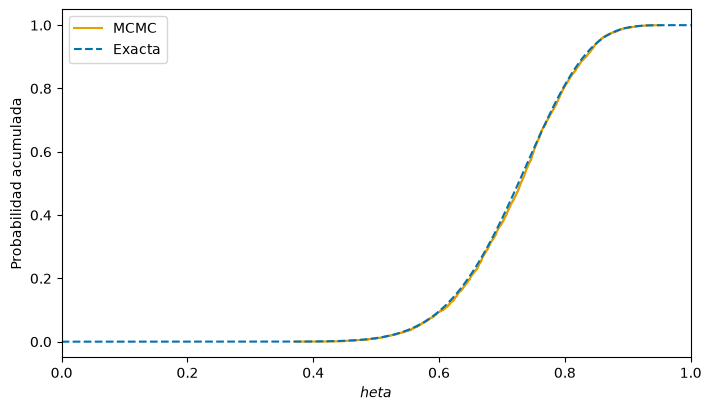

In [19]:
theta_ordenadas = np.sort(theta_muestras.stack(sample=("chain", "draw")).to_numpy())
prob_acumulada = np.arange(1, theta_ordenadas.size + 1) / theta_ordenadas.size
theta_grid = np.linspace(0, 1, 500)

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.step(theta_ordenadas, prob_acumulada, where="post", color=COLORES[1], label="MCMC")
ax.plot(theta_grid, posterior_exacto.cdf(theta_grid), color=COLORES[0], ls="--", label="Exacta")
ax.set(xlabel=r"$	heta$", ylabel="Probabilidad acumulada", xlim=(0, 1))
ax.legend();

## Distribución predictiva _a posteriori_

**¿Cuántos tiros podría acertar Caleb en un nuevo conjunto de intentos?** Además de la incertidumbre sobre $\theta$, tenemos la variabilidad de los tiros futuros. Para $m$ nuevos intentos:

$$
p(\tilde y\mid y)=\int p(\tilde y\mid\theta)\,p(\theta\mid y)\,d\theta.
$$

Aproximamos esta mezcla en dos pasos: tomamos un valor $\theta_s$ del _posterior_ y generamos $\tilde Y_s\sim\operatorname{Binomial}(m,\theta_s)$. Repetimos para todas las extracciones. `pm.sample_posterior_predictive()` realiza esa simulación usando el modelo y las muestras disponibles. El conteo observado permanece fijo en la inferencia de $\theta$.

Primero mantenemos $m=23$, la cantidad original de intentos. Obtenemos **réplicas del conteo observado**, útiles para comparar el comportamiento del modelo con los datos.

`extend_inferencedata=True` agrega el grupo `posterior_predictive` a `idata`. Aunque el argumento conserva ese nombre, el objeto actual es un `DataTree`. `var_names=["y"]` pide simular la variable observacional usando las muestras de $\theta$.

In [20]:
with modelo:
    pm.sample_posterior_predictive(
        idata,
        var_names=["y"],
        random_seed=SEMILLA + 1,
        extend_inferencedata=True,
    )

idata["posterior_predictive"]

Sampling: [y]


Output()

<xarray.DataTree 'posterior_predictive'>
Group: /posterior_predictive
    Dimensions:  (chain: 4, draw: 1000)
    Coordinates:
      * chain    (chain) int64 32B 0 1 2 3
      * draw     (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
    Data variables:
        y        (chain, draw) int64 32kB 13 14 19 19 22 21 19 ... 18 18 18 21 12 15
    Attributes:
        created_at:                 2026-11-27T22:09:52.005152+00:00
        creation_library:           ArviZ
        creation_library_version:   1.3.1
        creation_library_language:  Python
        inference_library:          pymc
        inference_library_version:  6.3.2
        sample_dims:                ['chain', 'draw']

La variable simulada se llama `y`, como en el modelo, y tiene un conteo por cada pareja de cadena y extracción. Para estimar su masa de probabilidad usamos `np.bincount()`, que cuenta cuántas veces apareció cada entero, y dividimos por la cantidad total de simulaciones. La función de masa se representa con bastones y puntos.

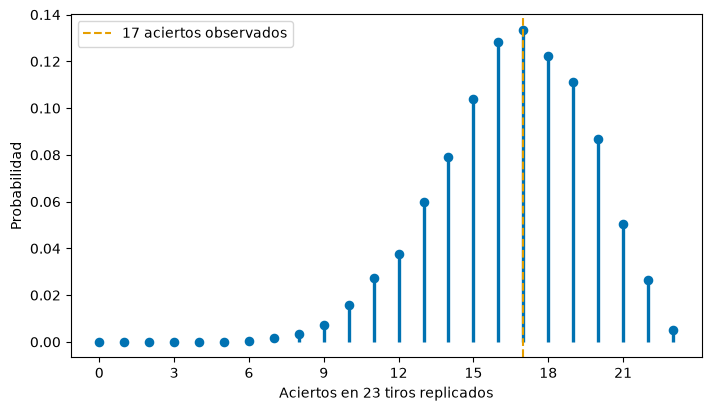

In [21]:
replicas = idata["posterior_predictive"]["y"]
conteos_replicados = np.arange(n_caleb + 1)
masa_replicada = np.bincount(replicas.to_numpy().ravel(), minlength=n_caleb + 1) / replicas.size

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.vlines(conteos_replicados, 0, masa_replicada, color=COLORES[0], linewidth=2.4)
ax.scatter(conteos_replicados, masa_replicada, color=COLORES[0], s=35)
ax.axvline(y_caleb, color=COLORES[1], ls="--", label="17 aciertos observados")
ax.set(xlabel="Aciertos en 23 tiros replicados", ylabel="Probabilidad", xticks=np.arange(0, 24, 3))
ax.legend();

El conteo observado se compara con los resultados que el modelo considera plausibles para otra serie de 23 tiros. Esta comprobación tiene poco alcance: contamos con un único total agregado. Para examinar cambios entre partidos, cansancio o dependencia entre tiros necesitaríamos datos con ese detalle.

### Dos tiros nuevos

Para responder la pregunta de la clase anterior, cambiamos la cantidad de intentos a $m=2$ con `pm.set_data()`. Esta llamada modifica la cantidad conocida registrada en el modelo.

Las muestras de $\theta\mid y$ ya están calculadas. Las usamos para simular el nuevo escenario, sin volver a ajustar el modelo. `predictions=True` guarda el resultado en `predictions`, separado de las réplicas para el diseño original. Conservamos cada escenario en su propio árbol y restauramos los 23 intentos al terminar.

In [22]:
with modelo:
    pm.set_data({"n_intentos": 2})
    prediccion_dos = pm.sample_posterior_predictive(
        idata,
        var_names=["y"],
        predictions=True,
        random_seed=SEMILLA + 2,
    )
    pm.set_data({"n_intentos": n_caleb})

prediccion_dos

Sampling: [y]


Output()

<xarray.DataTree>
Group: /
├── Group: /predictions
│       Dimensions:  (chain: 4, draw: 1000)
│       Coordinates:
│         * chain    (chain) int64 32B 0 1 2 3
│         * draw     (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
│       Data variables:
│           y        (chain, draw) int64 32kB 2 0 2 2 2 2 2 2 2 1 ... 2 2 2 1 2 1 2 1 1
│       Attributes:
│           created_at:                 2026-11-27T22:09:52.235151+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.2
│           sample_dims:                ['chain', 'draw']
└── Group: /predictions_constant_data
        Dimensions:     ()
        Data variables:
            n_intentos  float64 8B 2.0
        Attributes:
            created_at:                 2026-11-27T22:09:52.236357+00:00
            creation_library:           ArviZ
            creation_library_version:   1.3.1
            creation_library_language:  Python
            inference_library:          pymc
            inference_library_version:  6.3.2
            sample_dims:                []

En este modelo, la referencia exacta es $\tilde Y\mid y\sim\operatorname{BetaBinomial}(2,18,7)$. La probabilidad de acertar ambos tiros se estima con la proporción de simulaciones iguales a 2. Con PreliZ usamos `.pdf(2)` para evaluar la masa exacta en ese valor.

In [23]:
tiros_dos = prediccion_dos["predictions"]["y"]
predictiva_dos_exacta = pz.BetaBinomial(n=2, alpha=alpha_posterior, beta=beta_posterior)

print(f"P(dos aciertos | y), simulada: {(tiros_dos == 2).mean().item():.4f}")
print(f"P(dos aciertos | y), exacta: {predictiva_dos_exacta.pdf(2):.4f}")
print(f"Plug-in con la media posterior: {media_exacta**2:.4f}")

P(dos aciertos | y), simulada: 0.5210
P(dos aciertos | y), exacta: 0.5262
Plug-in con la media posterior: 0.5184


La predictiva promedia $\theta^2$ sobre el _posterior_: $P(\tilde Y=2\mid y)=\mathbb E(\theta^2\mid y)$. El cálculo _plug-in_ fija $\theta$ en su media y usa $[\mathbb E(\theta\mid y)]^2$. La diferencia es $\operatorname{Var}(\theta\mid y)$, que recoge incertidumbre sobre la probabilidad de acierto.

### Veinte tiros nuevos

Ahora queremos $P(\tilde Y>15\mid y)$ para $m=20$. Repetimos la simulación para ese escenario. Como el conteo es entero, **más de 15** reúne los valores 16, 17, 18, 19 y 20.

In [24]:
m_nuevos = 20

with modelo:
    pm.set_data({"n_intentos": m_nuevos})
    prediccion_veinte = pm.sample_posterior_predictive(
        idata,
        var_names=["y"],
        predictions=True,
        random_seed=SEMILLA + 3,
    )
    pm.set_data({"n_intentos": n_caleb})

tiros_veinte = prediccion_veinte["predictions"]["y"]

Sampling: [y]


Output()

Comparemos la masa simulada con la beta-binomial exacta. Usamos dos paneles con la misma escala vertical y destacamos los valores que forman la probabilidad de interés.

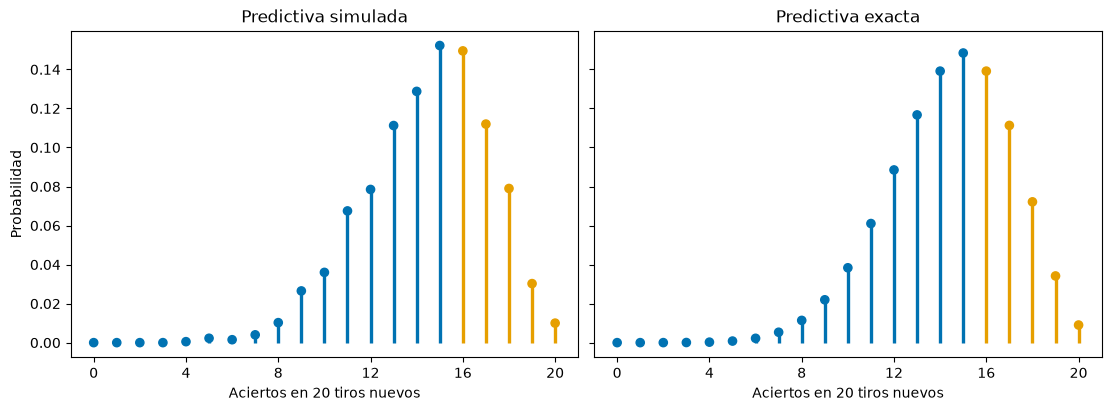

In [25]:
predictiva_veinte_exacta = pz.BetaBinomial(n=m_nuevos, alpha=alpha_posterior, beta=beta_posterior)
conteos_nuevos = np.arange(m_nuevos + 1)
masa_simulada = (
    np.bincount(tiros_veinte.to_numpy().ravel(), minlength=m_nuevos + 1) / tiros_veinte.size
)
masa_exacta = predictiva_veinte_exacta.pdf(conteos_nuevos)
colores_conteos = np.where(conteos_nuevos > 15, COLORES[1], COLORES[0])
masas = [masa_simulada, masa_exacta]
titulos = ["Predictiva simulada", "Predictiva exacta"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, layout="constrained")
for ax, masa, titulo in zip(axes, masas, titulos):
    ax.vlines(conteos_nuevos, 0, masa, color=colores_conteos, linewidth=2.4)
    ax.scatter(conteos_nuevos, masa, color=colores_conteos, s=35, zorder=3)
    ax.set(title=titulo, xlabel="Aciertos en 20 tiros nuevos", xticks=np.arange(0, 21, 4))
axes[0].set_ylabel("Probabilidad");

In [26]:
prob_veinte_simulada = (tiros_veinte > 15).mean().item()
prob_veinte_exacta = 1 - predictiva_veinte_exacta.cdf(15)

print(f"P(más de 15 aciertos | y), simulada: {prob_veinte_simulada:.4f}")
print(f"P(más de 15 aciertos | y), exacta: {prob_veinte_exacta:.4f}")

P(más de 15 aciertos | y), simulada: 0.3807
P(más de 15 aciertos | y), exacta: 0.3658


La proporción simulada aproxima la suma de las masas destacadas. El complemento de la CDF exacta en 15 calcula esa misma probabilidad. En la salida guardada obtenemos aproximadamente 0.381 mediante simulación y 0.366 con la beta-binomial. La simulación combina el error de aproximar el _posterior_ con la variabilidad de generar un conteo futuro por extracción. Al repetir el cálculo, la estimación puede cambiar.

El **IC de $\theta$** resume incertidumbre sobre la probabilidad de encestar. La **distribución de $\tilde Y$** describe aciertos futuros e incorpora también la variabilidad de los tiros. El **MCSE** mide precisión numérica al aproximar un resumen. Para evaluar el error Monte Carlo de la probabilidad predictiva necesitamos analizar el indicador `tiros_veinte > 15`, conservando los ejes de muestreo.

## Flujo de trabajo

Escribimos el modelo con `pm.Model()`, distribuciones y datos observados. Después usamos `pm.sample()` para generar cadenas y conservamos su estructura en un `DataTree`.

Antes de interpretar los resúmenes revisamos trazas, autocorrelación, R-hat y advertencias del muestreador. Con ESS y MCSE evaluamos la precisión de las cantidades que queremos informar. En este ejemplo pudimos comparar además con una solución exacta.

Finalmente, `pm.sample_posterior_predictive()` permitió simular réplicas para 23 tiros y predecir escenarios de 2 y 20 tiros, integrando la incertidumbre del _posterior_ de `theta`. Las conclusiones siguen dependiendo de los supuestos de independencia condicional y probabilidad constante.